In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/Dataset.csv")
print(df.shape)
df.head()

(8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [2]:
df = df.drop_duplicates(subset=["title", "type", "release_year"])
df = df.replace("Not Given", np.nan)
print(df.shape)
print(df["type"].value_counts())
print(df["type"].value_counts(normalize=True).round(3))

(8787, 10)
type
Movie      6124
TV Show    2663
Name: count, dtype: int64
type
Movie      0.697
TV Show    0.303
Name: proportion, dtype: float64


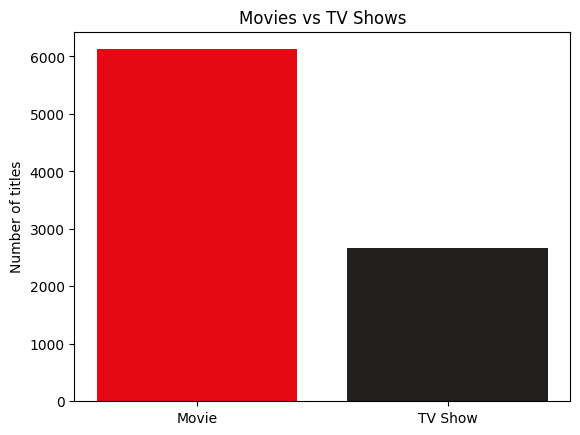

In [3]:
counts = df["type"].value_counts()
plt.bar(counts.index, counts.values, color=["#E50914", "#221F1F"])
plt.title("Movies vs TV Shows")
plt.ylabel("Number of titles")
plt.savefig("../screenshots/01_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
df["duration_unit"] = df["duration"].str.split().str[1]
print(pd.crosstab(df["duration_unit"], df["type"]))

type           Movie  TV Show
duration_unit                
Season             0     1790
Seasons            0      873
min             6124        0


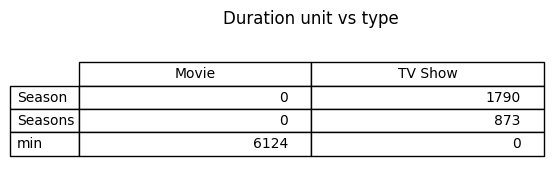

In [5]:
def save_table(table, filename, title=""):
    fig, ax = plt.subplots(figsize=(6, 0.8 + 0.4 * len(table)))
    ax.axis("off")
    t = ax.table(cellText=table.values, colLabels=table.columns,
                 rowLabels=table.index, loc="center")
    t.scale(1, 1.4)
    ax.set_title(title)
    plt.savefig(f"../screenshots/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

leak = pd.crosstab(df["duration_unit"], df["type"])
save_table(leak, "02_leakage_demo.png", "Duration unit vs type")

In [6]:
print(df.isnull().sum())
print()
print(df["rating"].value_counts())
print()
print(df["country"].value_counts().head(10))

show_id             0
type                0
title               0
director         2587
country           287
date_added          0
release_year        0
rating              0
duration            0
listed_in           0
duration_unit       0
dtype: int64

rating
TV-MA       3205
TV-14       2155
TV-PG        861
R            798
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


In [7]:
data = pd.DataFrame()

data["release_year"] = df["release_year"]

dates = pd.to_datetime(df["date_added"], errors="coerce")
data["year_added"] = dates.dt.year
data["month_added"] = dates.dt.month

data["has_director"] = df["director"].notna().astype(int)

data["rating"] = df["rating"].fillna("Unknown")

data["country"] = df["country"].fillna("Unknown").str.split(",").str[0].str.strip()
top = data["country"].value_counts().head(10).index
data["country"] = data["country"].where(data["country"].isin(top), "Other")

data["year_added"] = data["year_added"].fillna(data["year_added"].median())
data["month_added"] = data["month_added"].fillna(data["month_added"].median())

print(data.shape)
print(data.isnull().sum())
data.head()

(8787, 6)
release_year    0
year_added      0
month_added     0
has_director    0
rating          0
country         0
dtype: int64


,release_year,year_added,month_added,has_director,rating,country
0,2020,2021,9,1,PG-13,United States
1,2021,2021,9,1,TV-MA,France
2,2021,2021,9,1,TV-MA,United States
3,2021,2021,9,1,TV-PG,Other
4,1993,2021,9,1,TV-MA,United States


In [8]:
import re

def clean_genres(text):
    parts = []
    for g in text.lower().split(","):
        g = re.sub(r"\b(tv|movies|shows)\b", "", g)
        g = re.sub(r"[^a-z ]", "", g)
        g = re.sub(r"\s+", "_", g.strip())
        if g:
            parts.append(g)
    return " ".join(parts)

df["genres_clean"] = df["listed_in"].apply(clean_genres)
df[["listed_in", "genres_clean"]].head(8)

,listed_in,genres_clean
0,Documentaries,documentaries
1,"Crime TV Shows, International TV Shows, TV Act...",crime international action_adventure
2,"TV Dramas, TV Horror, TV Mysteries",dramas horror mysteries
3,"Children & Family Movies, Comedies",children_family comedies
4,"Dramas, Independent Movies, International Movies",dramas independent international
5,"British TV Shows, Reality TV",british reality
6,"Comedies, Dramas",comedies dramas
7,"Children & Family Movies, Comedies, Music & Mu...",children_family comedies music_musicals


In [9]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(token_pattern=r"\S+", binary=True)
genre_matrix = cv.fit_transform(df["genres_clean"])
genre_df = pd.DataFrame(genre_matrix.toarray(),
                        columns=["genre_" + g for g in cv.get_feature_names_out()],
                        index=df.index)

X_base = pd.get_dummies(data, columns=["rating", "country"], dtype=int)
X = pd.concat([X_base, genre_df], axis=1)

y = (df["type"] == "TV Show").astype(int)

print("X shape:", X.shape)
print("TV Show = 1, Movie = 0")
print(y.value_counts())
X.head()

X shape: (8787, 61)
TV Show = 1, Movie = 0
type
0    6124
1    2663
Name: count, dtype: int64


,release_year,year_added,month_added,has_director,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,...,genre_reality,genre_romantic,genre_science_nature,genre_scifi_fantasy,genre_spanishlanguage,genre_sports,genre_standup_comedy,genre_standup_comedy_talk,genre_teen,genre_thrillers
0,2020,2021,9,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,2021,2021,9,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2021,2021,9,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2021,2021,9,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1993,2021,9,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [10]:
from sklearn.model_selection import train_test_split

idx_train, idx_test = train_test_split(
    X.index, test_size=0.2, random_state=42, stratify=y
)
y_train = y.loc[idx_train]
y_test = y.loc[idx_test]

print("Train size:", len(idx_train))
print("Test size:", len(idx_test))
print("TV Show share in train:", round(y_train.mean(), 3))
print("TV Show share in test:", round(y_test.mean(), 3))

Train size: 7029
Test size: 1758
TV Show share in train: 0.303
TV Show share in test: 0.303


In [11]:
dur_num = df["duration"].str.extract(r"(\d+)")[0].astype(int)
dur_is_min = df["duration"].str.contains("min").astype(int)

X_leaky = X.copy()
X_leaky["duration_num"] = dur_num
X_leaky["duration_is_min"] = dur_is_min

genre_cols = [c for c in X.columns if c.startswith("genre_")]
X_strict = X.drop(columns=genre_cols)

feature_sets = {
    "1 Leaky (with duration)": X_leaky,
    "2 Honest (no duration)": X,
    "3 Strict (no duration, no genres)": X_strict,
}

for name, f in feature_sets.items():
    print(name, "->", f.shape)

baseline = 1 - y_test.mean()
print("Baseline (always say Movie):", round(baseline, 3))

1 Leaky (with duration) -> (8787, 63)
2 Honest (no duration) -> (8787, 61)
3 Strict (no duration, no genres) -> (8787, 29)
Baseline (always say Movie): 0.697


In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

rows = []
for exp_name, Xf in feature_sets.items():
    for model_name, model in models.items():
        model.fit(Xf.loc[idx_train], y_train)
        pred = model.predict(Xf.loc[idx_test])
        rows.append({
            "Experiment": exp_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
        })

results = pd.DataFrame(rows).round(3)
results

,Experiment,Model,Accuracy,Precision,Recall,F1
0,1 Leaky (with duration),Logistic Regression,1.000,1.000,1.000,1.000
1,1 Leaky (with duration),Decision Tree,1.000,1.000,1.000,1.000
2,1 Leaky (with duration),Random Forest,1.000,1.000,1.000,1.000
3,1 Leaky (with duration),KNN,0.994,0.996,0.985,0.991
4,2 Honest (no duration),Logistic Regression,0.989,0.979,0.983,0.981
5,2 Honest (no duration),Decision Tree,0.978,0.964,0.964,0.964
6,2 Honest (no duration),Random Forest,0.987,0.979,0.979,0.979
7,2 Honest (no duration),KNN,0.971,0.965,0.938,0.951
8,"3 Strict (no duration, no genres)",Logistic Regression,0.948,0.933,0.893,0.913
9,"3 Strict (no duration, no genres)",Decision Tree,0.918,0.876,0.848,0.862


                     1 Leaky  2 Honest  3 Strict
Model                                           
Decision Tree          1.000     0.978     0.918
KNN                    0.994     0.971     0.939
Logistic Regression    1.000     0.989     0.948
Random Forest          1.000     0.987     0.940
Baseline: 0.697


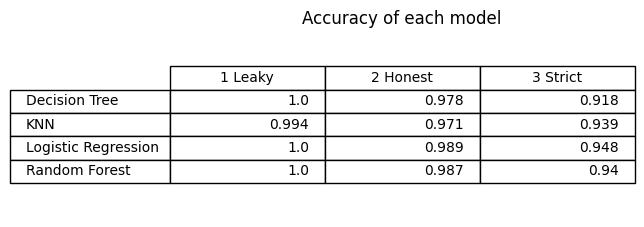

In [13]:
acc = results.pivot(index="Model", columns="Experiment", values="Accuracy")
acc.columns = ["1 Leaky", "2 Honest", "3 Strict"]
print(acc)
print("Baseline:", round(baseline, 3))
save_table(acc, "03_model_comparison_table.png", "Accuracy of each model")

## Feature selection

| Column | Decision | Reason |
|---|---|---|
| show_id, title | Dropped | Only names and IDs, nothing to learn from |
| type | Target | This is what we predict (Movie = 0, TV Show = 1) |
| duration | Dropped | Leaks the answer ("min" is only Movies, "Season" is only TV Shows) |
| listed_in (genres) | Kept, cleaned | Removed the words "tv", "movies" and "shows" first |
| country | Kept | First country only, top 10 plus "Other" |
| director | Kept as yes/no | Thousands of names, so only "has a director" is used |
| rating | Kept | One-hot encoded |
| release_year, date_added | Kept | Year and month used |

## Three experiments
1. **Leaky:** with duration (shows the cheating)
2. **Honest:** no duration, cleaned genres
3. **Strict:** no duration and no genres (the most trustworthy)


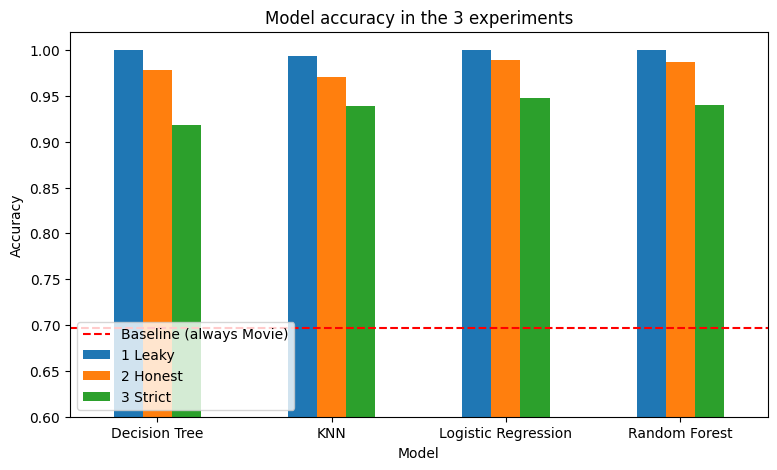

In [14]:
def save_fig(filename):
    plt.savefig(f"../screenshots/{filename}", dpi=150, bbox_inches="tight")

acc.plot(kind="bar", figsize=(9, 5), rot=0)
plt.axhline(baseline, color="red", linestyle="--", label="Baseline (always Movie)")
plt.ylim(0.6, 1.02)
plt.ylabel("Accuracy")
plt.title("Model accuracy in the 3 experiments")
plt.legend(loc="lower left")
save_fig("04_model_comparison.png")
plt.show()

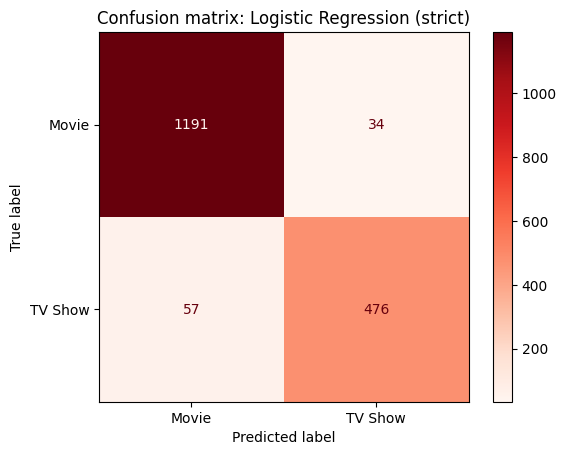

              precision    recall  f1-score   support

       Movie       0.95      0.97      0.96      1225
     TV Show       0.93      0.89      0.91       533

    accuracy                           0.95      1758
   macro avg       0.94      0.93      0.94      1758
weighted avg       0.95      0.95      0.95      1758



In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best = models["Logistic Regression"]
best.fit(X_strict.loc[idx_train], y_train)
pred = best.predict(X_strict.loc[idx_test])

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Movie", "TV Show"], cmap="Reds"
)
plt.title("Confusion matrix: Logistic Regression (strict)")
save_fig("05_confusion_matrix.png")
plt.show()

print(classification_report(y_test, pred, target_names=["Movie", "TV Show"]))

In [16]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for exp_name in ["2 Honest (no duration)", "3 Strict (no duration, no genres)"]:
    Xf = feature_sets[exp_name]
    for model_name, model in models.items():
        scores = cross_val_score(model, Xf, y, cv=cv5, scoring="accuracy")
        cv_rows.append({
            "Experiment": exp_name,
            "Model": model_name,
            "Mean accuracy": scores.mean(),
            "Std": scores.std(),
        })

cv_results = pd.DataFrame(cv_rows).round(3)
cv_results

,Experiment,Model,Mean accuracy,Std
0,2 Honest (no duration),Logistic Regression,0.989,0.002
1,2 Honest (no duration),Decision Tree,0.979,0.002
2,2 Honest (no duration),Random Forest,0.987,0.002
3,2 Honest (no duration),KNN,0.974,0.006
4,"3 Strict (no duration, no genres)",Logistic Regression,0.952,0.004
5,"3 Strict (no duration, no genres)",Decision Tree,0.922,0.003
6,"3 Strict (no duration, no genres)",Random Forest,0.945,0.004
7,"3 Strict (no duration, no genres)",KNN,0.946,0.003


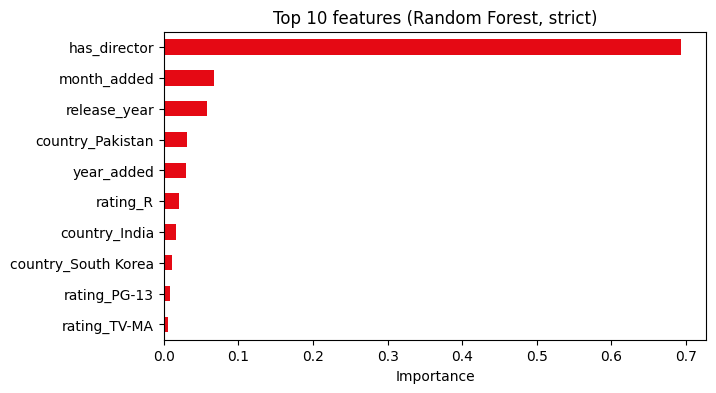

In [17]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_strict.loc[idx_train], y_train)

imp = pd.Series(rf.feature_importances_, index=X_strict.columns)
imp = imp.sort_values().tail(10)

imp.plot(kind="barh", figsize=(7, 4), color="#E50914")
plt.title("Top 10 features (Random Forest, strict)")
plt.xlabel("Importance")
save_fig("06_feature_importance.png")
plt.show()